# Lab 01: How to call a model and read the response

## Goal

Send one list of messages to a model, read the reply as an object, and work out what the call cost. We start in a
playground: a recipe for pancakes, a football fan called Sam and a joke about guacamole. Two things happen there that
every program built on a model has to handle. A reply is cut off in the middle of a sentence and the call raises no
error. And a second call includes nothing from the first one, until our code sends the history itself. Then the
same call goes to work at a support desk, where a customer was charged twice, and we price the conversation.

## What you will learn

- How to build a message list with `system` and `user` roles and send it with `client.chat.completions.create`.
- How to read a `ChatCompletion` field by field: the reply's text, `finish_reason` and `usage`.
- How to notice a reply that was cut off, when the call raises no error.
- What a token is, seen as the pieces of a streamed reply.
- Why a new call includes nothing from the last one, and how sending the history makes a conversation.
- How to price a conversation from its usage and the prices in `models.env`.
- How the same call looks on the Responses API.

⚠️ Every cell that calls the model spends a little money on your key. This notebook makes fewer than twenty short
calls; together they cost well under one US cent at the prices in `models.env`.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model name from `models.env`, and
takes the key from `.env` without printing it.


In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")


model: gpt-6-luna | reasoning effort: none | key found: yes


Next, the client. `OpenAI()` reads `OPENAI_API_KEY` from the environment by itself, so we never pass the key in or
print it. The client holds the key and the address of the API. It sends nothing until we call one of its methods.


In [2]:
from openai import OpenAI

client = OpenAI()
print(type(client).__name__, "| sends requests to", client.base_url)


OpenAI | sends requests to https://api.openai.com/v1/


---

## Part A: Send a message list and read the reply as an object

Every program built on a model, from a chat page to an agent, repeats one operation: our code sends a list of
messages to a model and gets one reply back. We do it once, on a question about food, and look closely at what we send and at everything that comes
back.

### The message list

A message is a Python dictionary with two keys, `role` and `content`. There are three roles:

- `system`: the standing instruction, such as who the assistant is and how long its answers should be.
- `user`: the request for this turn.
- `assistant`: a reply the model gave earlier. We send one back ourselves in Part D.

The list is ordered: the system message first, then the turns in the order they happened. Our first list holds two
messages: an instruction for a home cook, and a request for a recipe. Pancakes are a classic breakfast: batter cooked
on a griddle, served with butter and syrup.


In [3]:
# SYSTEM: the standing instruction; QUESTION: this turn's request; messages: the list we send, in order
SYSTEM = {
    "role": "system",
    "content": "You are a friendly home cook. Answer in plain text, one short sentence per step.",
}
QUESTION = {"role": "user", "content": "Give me a recipe for pancakes in three steps."}
messages = [SYSTEM, QUESTION]

for message in messages:
    print(f'{message["role"]:>6}: {message["content"]}')


system: You are a friendly home cook. Answer in plain text, one short sentence per step.
  user: Give me a recipe for pancakes in three steps.


Two dictionaries, in order. (`:>6` in the f-string right-aligns each role in six characters, so the lines line up.)
That list is the whole input to the call. The model is sent nothing else: no earlier cell, no file and no previous
call.

### One call to `chat.completions.create`

The call takes three arguments:

- `model=MODEL`: the model name from `models.env`.
- `messages=messages`: the list above.
- `reasoning_effort=EFFORT or omit`: a setting from `models.env` that this model needs. Going further, at the end
  of the notebook, shows what it does.


In [4]:
from openai import omit

response = client.chat.completions.create(
    model=MODEL,
    messages=messages,
    reasoning_effort=EFFORT or omit,
)

print(response.choices[0].message.content)


1. Whisk 1 cup flour, 1 tablespoon sugar, 1 teaspoon baking powder, and a pinch of salt with 1 egg, ¾ cup milk, and 2 tablespoons melted butter.
2. Heat a lightly greased pan over medium heat and pour in about ¼ cup batter for each pancake.
3. Cook until bubbles form, flip, and cook until golden on the other side.


A recipe in three numbered steps, each one sentence, as the system message asked: whisk the batter, pour into a greased pan over medium heat, flip when bubbles form and cook until golden. The system message set the form of the answer and the user message set its subject.

To print the text we wrote `response.choices[0].message.content`. So `response` is not a string: the text is one field, a few levels down. Here is the type of `response`, and the whole object.

- `model_dump()` turns the object into plain Python dictionaries and lists.
- `exclude_none=True` leaves out the fields that are empty (`None`) on this call, so the dump stays short.
- `json.dumps(..., indent=2)` prints it one field per line.


In [5]:
import json

print(type(response))
print(json.dumps(response.model_dump(exclude_none=True), indent=2))


<class 'openai.types.chat.chat_completion.ChatCompletion'>
{
  "id": "chatcmpl-Ejm8YyrnywJuAHpUOJ6DlX1qadj8c",
  "choices": [
    {
      "finish_reason": "stop",
      "index": 0,
      "message": {
        "content": "1. Whisk 1 cup flour, 1 tablespoon sugar, 1 teaspoon baking powder, and a pinch of salt with 1 egg, \u00be cup milk, and 2 tablespoons melted butter.\n2. Heat a lightly greased pan over medium heat and pour in about \u00bc cup batter for each pancake.\n3. Cook until bubbles form, flip, and cook until golden on the other side.",
        "role": "assistant",
        "annotations": []
      }
    }
  ],
  "created": 1794578506,
  "model": "gpt-6-luna",
  "object": "chat.completion",
  "service_tier": "default",
  "usage": {
    "completion_tokens": 86,
    "prompt_tokens": 38,
    "total_tokens": 124,
    "completion_tokens_details": {
      "accepted_prediction_tokens": 0,
      "audio_tokens": 0,
      "reasoning_tokens": 0,
      "rejected_prediction_tokens": 0
    },
 

A `ChatCompletion`. Find each of these fields in the dump above; the middle column holds the values of our run.

| Field | In our run | What it holds |
|---|---|---|
| `id` | `chatcmpl-...` | The call's id, for logs |
| `model` | the model named in `models.env` | The model that answered |
| `choices` | a list of 1 | The replies. The API can return several for one request; we asked for one, so we read `choices[0]` |
| `choices[0].message.role` | `assistant` | Who wrote the message |
| `choices[0].message.content` | the recipe | The reply's text |
| `choices[0].finish_reason` | `stop` | Why the reply ended (Part B reads its values) |
| `usage.prompt_tokens` | 39 | How much text we sent, counted in tokens |
| `usage.completion_tokens` | 118 | How much text the model wrote, counted in tokens |
| `usage.total_tokens` | 157 | The two added together |

A **token** is the unit a model reads and writes: a piece of text, often a short word or part of a longer one.
Part C shows them. The two `..._details` blocks inside `usage` split the same counts further, and both are all
zeros here.

### Read the fields in code

A program does not read a dump. It reads the fields it needs. Two names make that shorter: `choice` for the first
reply and `usage` for the token counts of the whole call.


In [6]:
# choice: the first (and only) reply; usage: the token counts for the whole call
choice = response.choices[0]
usage = response.usage

print("role:             ", choice.message.role)
print("finish_reason:    ", choice.finish_reason)
print("prompt_tokens:    ", usage.prompt_tokens)
print("completion_tokens:", usage.completion_tokens)
print("total_tokens:     ", usage.total_tokens)


role:              assistant
finish_reason:     stop
prompt_tokens:     38
completion_tokens: 86
total_tokens:      124


`finish_reason` is `stop`: the model ended the reply itself. `total_tokens` is `prompt_tokens` plus `completion_tokens`: 38 + 86 = 124. These three fields are what the next parts read: `content` for the text, `finish_reason` before we trust it, and `usage` for the bill.

### The same call with no code: the Chat Playground

OpenAI's platform has a page that sends this request without any Python: the **Chat Playground**, at [platform.openai.com/chat](https://platform.openai.com/chat). Sign in with the account that owns your key, type the system message and the question, and send. The page makes the same kind of request and shows the reply. It is a quick place to try a system message before writing code for it, and the calls it makes are billed to the same account.

*Screenshot to add: the Chat Playground with the home-cook system message, the pancakes question and the reply.*

**Checkpoint A.** The reply is a three-step recipe. `response` is a `ChatCompletion` with `finish_reason: "stop"`. `usage` counts 38 prompt tokens for the two messages and around 90 completion tokens for the recipe (ours: 86).


---

## Part B: Notice a reply that was cut off without an error

A reply can stop before it is finished, and the call still succeeds. We make that happen on purpose, so that we
know what it looks like.

`max_completion_tokens` is one more argument of the call: the most the reply may use, counted in tokens. It is a
ceiling: a reply that reaches it is cut there.

Before you run the cell: the full recipe used about 90 tokens (ours: 86). What comes back when the
ceiling is 20?


In [7]:
short = client.chat.completions.create(
    model=MODEL,
    messages=messages,
    reasoning_effort=EFFORT or omit,
    max_completion_tokens=20,
)

print("finish_reason:    ", short.choices[0].finish_reason)
print("completion_tokens:", short.usage.completion_tokens)
print("content:          ", short.choices[0].message.content)


finish_reason:     length
completion_tokens: 20
content:           1. Whisk 1 cup flour, 1 tablespoon sugar, 1 teaspoon


`length`, exactly 20 tokens, and the text stops inside step 1: "1. Whisk 1 cup flour, 1 tablespoon sugar, 1 teaspoon". Ten words, and steps 2 and 3 never arrive.

**Notice** what did not happen: no exception and no warning. The call worked. If our code only printed `content`, the person who asked would get the start of a recipe and nothing to say that the rest is missing. The one sign is `finish_reason`:

- `stop`: the model ended the reply itself.
- `length`: the reply hit the ceiling and was cut.

There are a few other values (a reply blocked by a content filter, for example). These two are the ones we meet here.

So code that passes a reply on checks `finish_reason` first. Here is that check on both calls we have made.


In [8]:
for name, reply in [("no ceiling", response), ("ceiling of 20 tokens", short)]:
    if reply.choices[0].finish_reason == "length":
        print(f"❌ {name}: cut off at {reply.usage.completion_tokens} tokens")
    else:
        print(f"✅ {name}: finished on its own ({reply.choices[0].finish_reason})")


✅ no ceiling: finished on its own (stop)
❌ ceiling of 20 tokens: cut off at 20 tokens


A pass says the model ended the reply itself. It does not say the recipe is a good one.

**In production:** a program that shows a reply to a person checks `finish_reason` before it does. On `length` it
asks again with more room, or tells the person the answer is incomplete.

**Checkpoint B.** With a ceiling of 20 tokens: `finish_reason` is `length`, `completion_tokens` is 20, and the text
stops inside step 1. The check prints one pass line and one fail line.


---

## Part C: See tokens as the pieces of a streamed reply

The ceiling in Part B was counted in tokens, and so is the bill. We have used the word without seeing one. A
streamed reply shows them.

With `stream=True` the call does not wait for the whole reply. It returns a **stream**: an object a `for` loop can
pull items from, one at a time, as the model writes. Each item is a **chunk**, and a chunk carries a small piece of
new text in `chunk.choices[0].delta.content`.

Two details of the cell below:

- `stream_options={"include_usage": True}` asks for one extra chunk at the end that carries the `usage`. That last
  chunk has an empty `choices` list, so the loop checks `chunk.choices` before it reads `choices[0]`. Some chunks
  carry no text (the first one only names the role), so the loop also checks that `delta.content` is not empty.
- `print(piece, end="|")` prints each piece as it arrives, with a `|` after it instead of a new line, so we can see
  where one piece ends and the next begins.

The question is a short one this time, with no system message: a list with one `user` message is enough. Guacamole
is a dip made from mashed avocado, lime, and salt.


In [9]:
JOKE = {"role": "user", "content": "Tell me a one-line joke about guacamole."}

stream = client.chat.completions.create(
    model=MODEL,
    messages=[JOKE],
    reasoning_effort=EFFORT or omit,
    stream=True,
    stream_options={"include_usage": True},
)

# pieces: the text of each chunk, in the order it arrived; last_chunk: the final item of the stream
pieces = []
for chunk in stream:
    if chunk.choices and chunk.choices[0].delta.content:
        piece = chunk.choices[0].delta.content
        print(piece, end="|")
        pieces.append(piece)
    last_chunk = chunk


Gu|acamole| is| just| avocado|’s| way| of| saying|,| “|I|’m| better|

 with| chips|.”|

Read the first two pieces: `Gu|acamole|`. One word, two pieces. The model does not write words. It writes **tokens**, and a token is whatever piece of text its vocabulary holds: a common word such as ` is` or ` just` is one token (with the space in front of it), a word like `Guacamole` is two pieces, and punctuation gets pieces of its own.

**A token is a piece of text, not a word.** That is why a ceiling of 20 tokens cut the recipe after ten words, and why a bill counted in tokens is larger than a count of words suggests.

The loop kept every piece in the list `pieces` and the final chunk in `last_chunk`. We count the pieces, glue them back together with `"".join(pieces)`, and read the usage from the last chunk.


In [10]:
print("pieces:           ", len(pieces))
print("joined:           ", "".join(pieces))
print("last chunk choices:", last_chunk.choices)
print("prompt_tokens:    ", last_chunk.usage.prompt_tokens)
print("completion_tokens:", last_chunk.usage.completion_tokens)


pieces:            17
joined:            Guacamole is just avocado’s way of saying, “I’m better with chips.”
last chunk choices: []
prompt_tokens:     16
completion_tokens: 20


17 pieces, and joined they are the whole joke. The last chunk has no choices (`[]`) and carries the usage: 16 prompt tokens for our one-line question and 20 completion tokens. The count is three more than the 17 pieces we printed, and it was three more in every stream we ran. The API does not say what those three tokens are, and none of them showed up as text. Leave those three aside and each piece is one token, which is near enough to show what a token looks like.

Streaming changes when the words arrive, not what they cost: the tokens are the same as for a normal call. Chat pages stream so that a person sees the first words at once instead of waiting for the last one.

**Checkpoint C.** The joke prints in pieces with `|` between them, and `guacamole` is more than one piece (ours: two, `Gu|acamole|`). The last chunk has `choices` `[]` and a `usage` whose `completion_tokens` is close to the number of pieces (ours: 20 tokens for 17 pieces).


---

## Part D: Keep a conversation by sending the history

A chat has more than one turn: we say something, the model answers, we ask a follow-up. Each turn is a new call.
Does the second call include what we said in the first one?

Turn 1: Sam introduces himself. Arsenal is a football club in London. This call has no system message
either.


In [11]:
# turn_1: Sam's first message; first: the model's reply to it
turn_1 = {"role": "user", "content": "My name is Sam and I support Arsenal."}

first = client.chat.completions.create(
    model=MODEL,
    messages=[turn_1],
    reasoning_effort=EFFORT or omit,
)

print(first.choices[0].message.content)


Nice to meet you, Sam! Arsenal—good choice. 🔴⚪


A friendly greeting and an acknowledgement of the team. The reply repeats what we told it, because our one message is all the model was sent.

Turn 2 is a follow-up, sent as a new call with a new list that holds only the question. Before you run it: will the reply name the team?


In [12]:
turn_2 = {"role": "user", "content": "Which team do I support?"}

second = client.chat.completions.create(
    model=MODEL,
    messages=[turn_2],
    reasoning_effort=EFFORT or omit,
)

print(second.choices[0].message.content)
print("prompt_tokens:", second.usage.prompt_tokens)


I don’t know—you haven’t told me yet.
prompt_tokens: 12


The reply cannot name the team. In our run it says we have not told it yet. The prompt was 12 tokens: the
question and nothing else. (Twelve tokens for five words: every message also costs a few tokens for its role and
its wrapping.) "Sam" and "Arsenal" were never in this request, so the reply had nowhere to take them from.

**Chat Completions, the API we have been calling, keeps nothing between calls.** The first call's messages and the reply to them are in our Python
variables `turn_1` and `first`. Nothing of them is on the model's side.

So the fix is ours to make: we keep the list, and we send all of it every time. The history is the same kind of
list as in Part A, longer:

1. Sam's first message.
2. The model's reply to it, as a message with the role `assistant`. The text is `first.choices[0].message.content`.
3. The new question.

The print shows the first 70 characters of each message (`[:70]`).


In [13]:
# history: everything said so far, in order, with the model's reply sent back as an assistant message
history = [
    turn_1,
    {"role": "assistant", "content": first.choices[0].message.content},
    turn_2,
]

for message in history:
    print(f'{message["role"]:>9}: {message["content"][:70]}')


     user: My name is Sam and I support Arsenal.
assistant: Nice to meet you, Sam! Arsenal—good choice. 🔴⚪
     user: Which team do I support?


Three messages. The second is the text the model wrote in turn 1, and our code now sends it back. The model and the
question are the same as in the call that failed. Only the list is different.


In [14]:
with_history = client.chat.completions.create(
    model=MODEL,
    messages=history,
    reasoning_effort=EFFORT or omit,
)

print(with_history.choices[0].message.content)
print("prompt_tokens:", with_history.usage.prompt_tokens)


You support Arsenal.
prompt_tokens: 47


Now it answers "You support Arsenal." The model did not remember anything. It read "Arsenal" in the list we sent, a few lines above the question.

| Call | Messages sent | Prompt tokens | Names the team? |
|---|---|---|---|
| Turn 2 alone | 1 | 12 | no |
| Turn 2 with the history | 3 | 47 | yes |

**Lesson to Remember:** the message list is the conversation's memory, and our code holds it. Every chat product does this: the page keeps the list and sends all of it with each new question.

Notice the prompt tokens too. The longer list is billed in full, on every turn. Part F puts a price on that.

**Checkpoint D.** The call with only the question cannot name the team. With the history it answers Arsenal, and its prompt is several times longer (ours: 47 tokens against 12).


---

## Part E: Answer a customer across two turns at a support desk

So far the questions were for fun. Now the same call does a job. A customer of an online music shop writes to its
support desk, and the assistant that answers is a model behind a chat window.

Nothing in the mechanism changes: a system message for the desk, the customer's message, one call.


In [15]:
# DESK: the support desk's standing instruction; customer_1: the customer's first message
DESK = {
    "role": "system",
    "content": "You are a support assistant for an online music shop. Answer in one or two short sentences.",
}
customer_1 = {"role": "user", "content": "Hi, I was charged twice for my order, number 46."}

desk_first = client.chat.completions.create(
    model=MODEL,
    messages=[DESK, customer_1],
    reasoning_effort=EFFORT or omit,
)

print(desk_first.choices[0].message.content)
print("prompt_tokens:", desk_first.usage.prompt_tokens)


I’m sorry about that. I can’t access billing records here, but please contact our support team with order 46 and both charge dates/amounts so they can investigate and refund any duplicate charge.
prompt_tokens: 43


The reply apologises, says it cannot access billing records, and asks the customer to contact the support team
with order #46 and the dates and amounts of both charges. It can say no more than that. The model writes text from
the list it was sent, and that list has no billing records in it. The prompt was 43 tokens: the desk's
instruction and the customer's message.

Now the customer asks for something that depends on the first message. From Part D we know what our code has to
do: send the first turn again, with the model's reply to it, in front of the new message. So the second call has
four messages: the desk's instruction, the customer's first message, the assistant's reply, and the new request.


In [16]:
customer_2 = {"role": "user", "content": "Please write a one-line note about this for your billing team."}

desk_history = [
    DESK,
    customer_1,
    {"role": "assistant", "content": desk_first.choices[0].message.content},
    customer_2,
]

desk_second = client.chat.completions.create(
    model=MODEL,
    messages=desk_history,
    reasoning_effort=EFFORT or omit,
)

print(desk_second.choices[0].message.content)
print("prompt_tokens:", desk_second.usage.prompt_tokens)


Please investigate order 46: the customer reports being charged twice and requests a refund if a duplicate charge is confirmed.
prompt_tokens: 107


The note tells the billing team that a customer reports being charged twice for order #46. The request for the
note did not mention an order or a charge: "about this" could only be answered from the first turn, and the first
turn is in the second call only because our code sent it again.

The picture shows the two calls we just made.


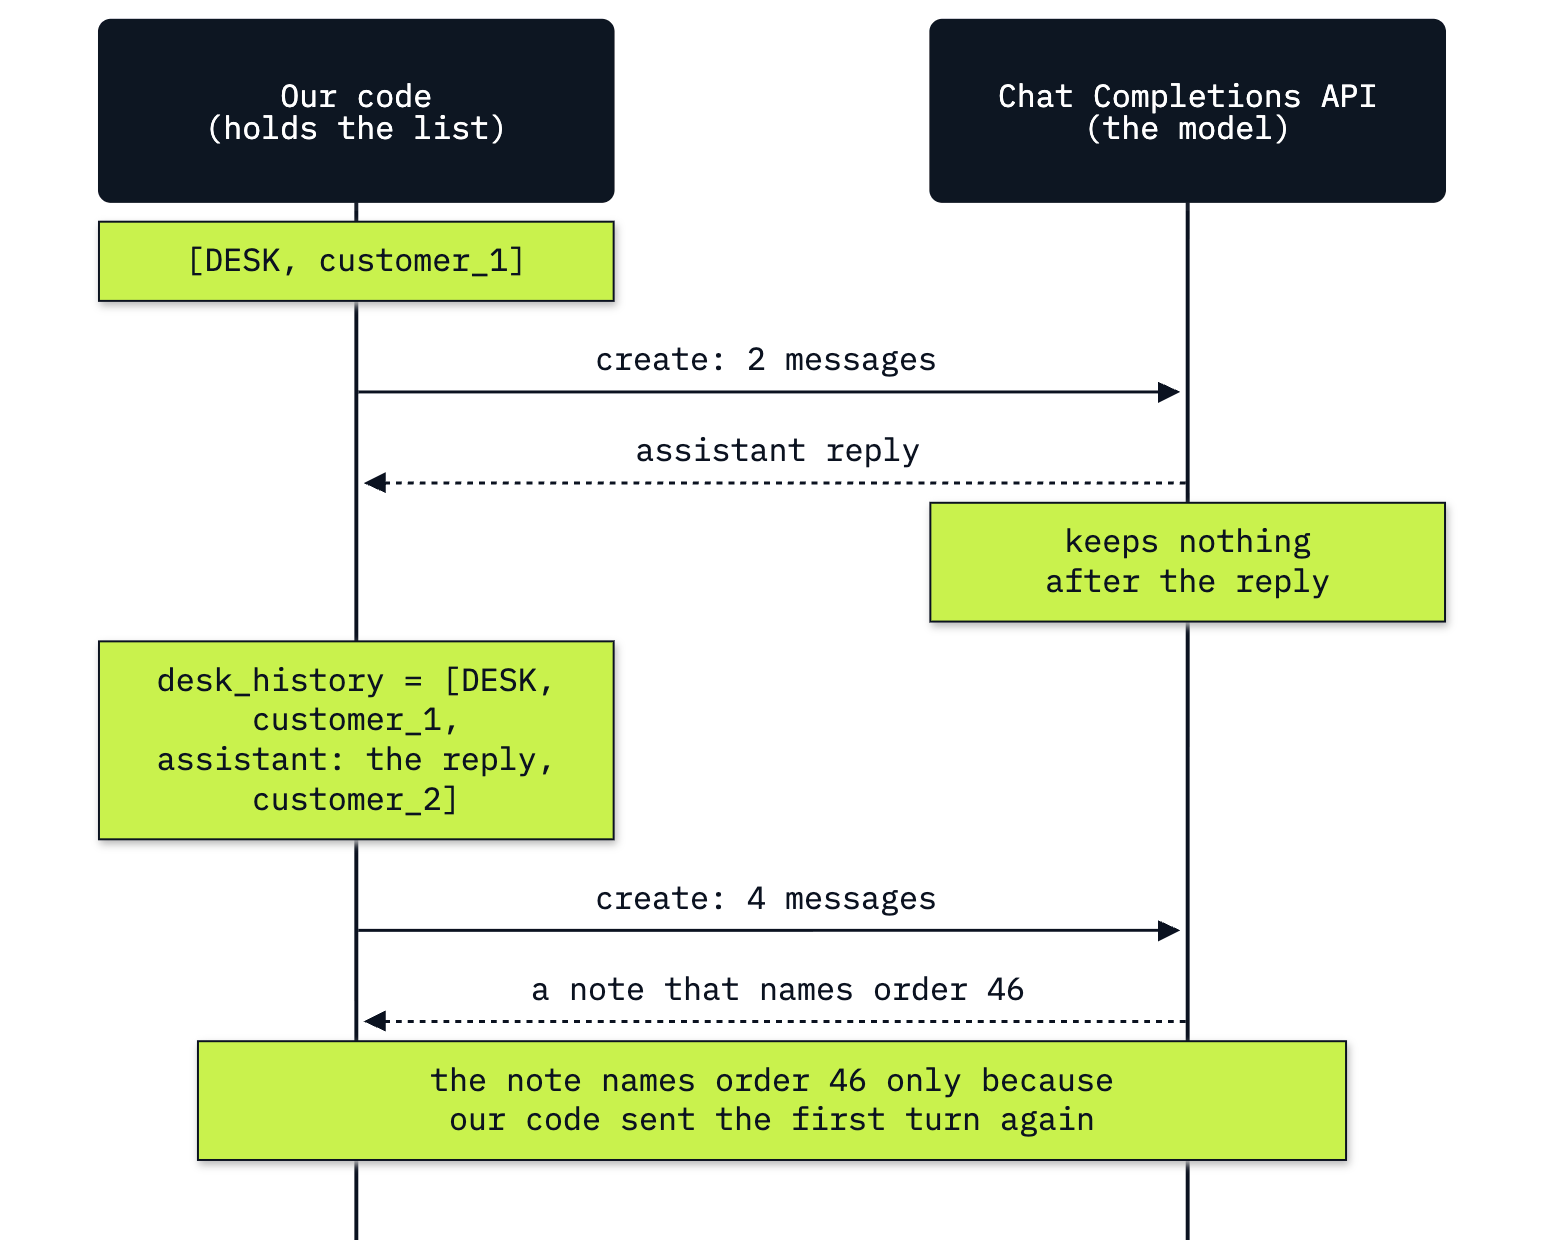

In [17]:
from IPython.display import Image

Image("resources/lab01_message_list.png", width=760)


How to read the picture: our code is on the left and holds the list (the lime notes on its side, with the names from our code). Each arrow to the right is one call, and it carries the whole list as it stands at that moment. The model,
on the right, answers from that list and keeps nothing afterwards.

Sending the first turn again has a cost. The first call's prompt was 43 tokens and the second call's was 107: the same 43,
plus the assistant's reply, plus the new request. The first turn was sent twice, and it would be sent again on a
third turn.

**Checkpoint E.** The first reply mentions order 46. The note for the billing team names
order 46 too, and the second call's prompt is more than twice the first (ours: 107 tokens against 43).


---

## Part F: Price the conversation from its usage

Every call is billed by its tokens: the tokens we send (input) and the tokens the model writes (output), each at
its own price. A support desk answers many customers, so the price of one conversation, multiplied, is what a
team needs to know before it puts a model behind a chat window.

`models.env` holds the list prices of the model, in US dollars per one million tokens. The setup cell read them
into `settings` as text; `float()` turns each into a number.


In [18]:
# Dollars per 1 million tokens, from models.env
PRICE_INPUT = float(settings["PRICE_INPUT_PER_MILLION"])
PRICE_OUTPUT = float(settings["PRICE_OUTPUT_PER_MILLION"])

print("input:", PRICE_INPUT, "| output:", PRICE_OUTPUT)


input: 0.1 | output: 0.5


Two prices: \$0.10 for a million input tokens and \$0.50 for a million output tokens. On this model a token the
model writes costs five times as much as a token we send.

The conversation was two calls, so we add up their tokens: the prompt tokens of both calls are the input, and the
completion tokens of both are the output.


In [19]:
# The whole conversation: both calls' prompt tokens are input, both calls' completion tokens are output
input_tokens = desk_first.usage.prompt_tokens + desk_second.usage.prompt_tokens
output_tokens = desk_first.usage.completion_tokens + desk_second.usage.completion_tokens

print("input tokens: ", desk_first.usage.prompt_tokens, "+", desk_second.usage.prompt_tokens, "=", input_tokens)
print("output tokens:", desk_first.usage.completion_tokens, "+", desk_second.usage.completion_tokens, "=", output_tokens)


input tokens:  43 + 107 = 150
output tokens: 44 + 26 = 70


The price of the conversation:

$$\text{cost} = \frac{\text{input tokens} \times \text{input price} + \text{output tokens} \times \text{output price}}{1{,}000{,}000}$$

With our numbers:

$$\text{cost} = \frac{ 150 \times 0.10 + 70 \times 0.50 }{1{,}000{,}000} = \$0.0000500$$

The same in code (`1_000_000` is one million; Python ignores the underscores), for one conversation and for
100,000 of them:


In [20]:
cost = (input_tokens * PRICE_INPUT + output_tokens * PRICE_OUTPUT) / 1_000_000

print(f"one conversation:      ${cost:.7f}")
print(f"100,000 conversations: ${cost * 100_000:,.2f}")


one conversation:      $0.0000500
100,000 conversations: $5.00


One conversation costs \$0.0000484, a few thousandths of a cent. Nobody budgets for that. The number to watch is
the multiplier: 100,000 customers with the same two-turn problem cost \$4.84.

Notice where the input tokens come from. Of the 150, the first turn's 43 were paid for twice, once in each call.
A conversation's input tokens grow faster than the number of its turns, because every turn sends all the turns
before it again. A long system message, a long reply or a tenth turn moves the number quickly, and `usage` shows
it on every call, before the bill arrives. (Long prompts that repeat can be billed at a lower, cached price. Going
further shows it.)

**Checkpoint F.** Input and output prices printed from `models.env`; the conversation's input tokens are the two
prompts added together (ours: 150); one conversation costs a small fraction of a cent (ours: \$0.0000484) and
100,000 of them cost \$4.84.


---

## Part G: Make the same call on the Responses API

OpenAI has a second API for the same models, the **Responses API**, and recommends it for new projects. Here is
Part A's call on it, so that the two can be read side by side:

- `instructions` takes the text of the system message.
- `input` takes the user's message: a string, or a list of messages like ours.
- `reasoning={"effort": EFFORT or omit}` is the same setting as `reasoning_effort`, under another name.
- `reply.output_text` is the text of the reply.
- `store=False` keeps this call out of the account's stored responses. Going further shows what storing is for.


In [21]:
reply = client.responses.create(
    model=MODEL,
    instructions=SYSTEM["content"],
    input=QUESTION["content"],
    reasoning={"effort": EFFORT or omit},
    store=False,
)

print(reply.output_text)
print()
print("status:", reply.status, "| input_tokens:", reply.usage.input_tokens, "| output_tokens:", reply.usage.output_tokens)


1. Whisk 1 cup flour, 1 tablespoon sugar, 2 teaspoons baking powder, and a pinch of salt; stir in 1 cup milk, 1 egg, and 2 tablespoons melted butter until just combined.
2. Heat a lightly buttered pan over medium heat, pour in about ¼ cup batter per pancake, and cook until bubbles form.
3. Flip and cook until golden, then serve warm with your favorite toppings.

status: completed | input_tokens: 38 | output_tokens: 95


The same kind of recipe, with `status` `completed` where Chat Completions said `finish_reason` `stop`. The call
used 38 input tokens, as many as Part A's 38 prompt tokens, because the same text went in. The 95 output tokens
differ from Part A's 86 only because the model worded the recipe differently.

The fields we read in this lab, under both names:

| What | Chat Completions | Responses |
|---|---|---|
| Standing instruction | a `system` message in `messages` | `instructions` |
| The request | `messages`, a list | `input`, a string or a list |
| Ceiling on the reply | `max_completion_tokens` | `max_output_tokens` |
| The reply's text | `choices[0].message.content` | `output_text` |
| Why it ended | `finish_reason` (`stop`, `length`) | `status` (`completed`, `incomplete`) |
| Token counts | `prompt_tokens`, `completion_tokens` | `input_tokens`, `output_tokens` |

**Important:** this lab calls Chat Completions on purpose. It is the fundamental: we send the list ourselves, so
every message the model is sent is in our own code, where we can print it and count it. Many other model providers
accept the same message-list format. For new projects OpenAI recommends the Responses API, and agent frameworks
call it for us. It can also keep the history on OpenAI's side; Going further shows that, and what it costs.

**Checkpoint G.** `output_text` holds a three-step recipe; `status` is `completed`; `input_tokens` is
38, as many as Part A's `prompt_tokens`.


---

## What you can do now

- Build a message list with `system`, `user` and `assistant` messages and send it with
  `client.chat.completions.create` (Parts A and D).
- Read a `ChatCompletion`: the text in `choices[0].message.content`, why it ended in `finish_reason`, the token
  counts in `usage` (Part A).
- Catch a reply that was cut off, by checking for `length` before the reply is used (Part B).
- Say what a token is, and stream a reply piece by piece with its usage on the last chunk (Part C).
- Keep a conversation by sending the whole history, and say why the model has no memory of its own (Parts D and E).
- Price a conversation from its usage and the prices in `models.env`, for one customer or 100,000 (Part F).
- Make the same call on the Responses API and name its fields (Part G).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `StopIteration` in the setup cell | the notebook is not inside the repository folder, so no `models.env` was found above it | open the notebook from inside the repository folder |
| `AssertionError: Put OPENAI_API_KEY in .env at the repository folder (copy .env.example).` | there is no key in the environment or in `.env` | copy `.env.example` to `.env` in the repository folder and put your key in it |
| An empty reply with `finish_reason` `length` | the whole ceiling went to hidden reasoning tokens (Going further shows it) | keep `REASONING_EFFORT=none` in `models.env`, or raise `max_completion_tokens` |
| `400 ... 'max_tokens' is not supported with this model. Use 'max_completion_tokens' instead.` | `max_tokens` is the older name of the ceiling | use `max_completion_tokens` |
| Part B prints `stop` and a whole reply | another model answered in fewer than 20 tokens | lower `max_completion_tokens` and run the cell again |

## Challenge

Two tasks. Both use the support desk conversation of Part E (`DESK`, `customer_1`, `customer_2`, `desk_history`)
and the prices of Part F.

1. **Stream the note for the billing team, and price that call.** Send `desk_history` with `stream=True` and
   `stream_options={"include_usage": True}`, print the pieces as they arrive with `|` between them, then price the
   call from the last chunk's usage with Part F's formula. *Expected:* the streamed note names order 46; its
   `prompt_tokens` are the same as `desk_second`'s (ours: 107), because the list is the same; the price is
   about \$0.00002, two thousandths of a cent (our solution: \$0.0000245).
2. **Keep the two-turn conversation within a token budget.** Run the customer's two turns again (turn 1 alone, then
   turn 2 with the history) so that both calls together use at most 190 tokens (`total_tokens` added up),
   both end with `finish_reason` `stop`, and the note still names order 46. Print the total and a pass or fail line.
   *Expected:* with Part E's system message the two calls use about 200 to 230 tokens, so the conversation does
   not fit as it is. The first reply goes into the second prompt, so its length is paid for twice: a system
   message that asks for shorter replies brings the total under 190 without cutting a reply off (our
   solution: 182 tokens). A lower `max_completion_tokens` alone gets there only by cutting the first
   reply, and the `finish_reason` check from Part B catches that. If your run already fits, lower the budget by 20
   and try again.

The solution, run with its outputs, is in `solved/01_model_call_solution.ipynb`.


In [22]:
# Task 1: stream desk_history with include_usage, print the pieces, then price the call


Task 2 in the cell below.


In [23]:
# Task 2: two turns within the token budget, both ending with "stop", the note naming order 46


---

## Going further

Four short topics that Parts A to G left out. Each one stands alone, and no part above depends on them. The
first two are about one model family's settings, so each cell says what it does on a model that has no such
setting.

### What reasoning effort does to a small ceiling

Some models reason before they answer: they first write hidden **reasoning tokens**. We never see them in
`content`, but they are part of `completion_tokens`, so they count against `max_completion_tokens` and are billed
as output. `reasoning_effort` says how much reasoning is allowed: `none`, `low`, `medium` and higher.

`models.env` sets `none`, and `EFFORT or omit` passes that setting on every call in this notebook. When the
setting is empty, for a model without reasoning, `omit` leaves the argument out of the request. Here is Part B's
call again at effort `low`. (`!r` in the f-string prints the content
with its quotes, so an empty reply shows as `''`.)


In [24]:
if EFFORT is None:
    print("REASONING_EFFORT is empty in models.env: this model has no reasoning setting, so there is nothing to try.")
else:
    thought = client.chat.completions.create(
        model=MODEL,
        messages=messages,
        reasoning_effort="low",
        max_completion_tokens=20,
    )
    print("finish_reason:    ", thought.choices[0].finish_reason)
    print("completion_tokens:", thought.usage.completion_tokens)
    print("reasoning_tokens: ", thought.usage.completion_tokens_details.reasoning_tokens)
    print(f"content:           {thought.choices[0].message.content!r}")


finish_reason:     length
completion_tokens: 20
reasoning_tokens:  20
content:           ''


With reasoning allowed, the same 20-token ceiling gives an empty reply: `finish_reason` is `length`, and all 20
tokens went to reasoning, so nothing was left for the answer. This is Part B's cut-off reply in a worse form, and
the check is the same: read `finish_reason` before using `content`. It is also why the first call in Part A set
the effort from `models.env`.

### Two requests the API refuses

Some settings are refused before the model runs. The API answers with status 400, and the `openai` package raises
`BadRequestError`. `try` / `except` catches it, so we can read the API's explanation in `error.body["message"]`
instead of stopping the notebook.

We try two settings that older code often carries: `max_tokens`, the earlier name of the ceiling, and
`temperature`, which sets how random the wording is. The `**extra` in the call unpacks a dictionary into keyword
arguments, so each request is Part A's call plus the settings in that dictionary.


In [25]:
from openai import BadRequestError

# Each entry: what we try, and the settings added to Part A's call
attempts = [
    ("max_tokens instead of max_completion_tokens", {"max_tokens": 20, "reasoning_effort": EFFORT or omit}),
    ("temperature with reasoning switched on", {"temperature": 0.2, "reasoning_effort": "low" if EFFORT else omit}),
]

for label, extra in attempts:
    try:
        client.chat.completions.create(model=MODEL, messages=messages, **extra)
    except BadRequestError as error:
        print(f"{label}:\n  {error.status_code} {error.body['message']}")
    else:
        print(f"{label}:\n  accepted by this model")


max_tokens instead of max_completion_tokens:
  400 Unsupported parameter: 'max_tokens' is not supported with this model. Use 'max_completion_tokens' instead.


temperature with reasoning switched on:
  400 Unsupported value: 'temperature' does not support 0.2 with this model. Only the default (1) value is supported.


Both are refused, and each message says what to do: use `max_completion_tokens`, and leave `temperature` at its
default. (On this model `temperature` is accepted only when reasoning is switched off.) A 400 costs nothing, because
the model never ran.

### Cached input and cache writes

Part F used two prices. A long prompt has two more. When the start of a prompt is at least 1,024 tokens long, the
API stores it for a while (30 minutes by default), and a later call that begins with the same text reads it back
from that cache:

- **cache write**: the tokens stored on the first call, billed a little above the input price;
- **cached input**: the tokens read back on a later call, billed far below it.

Every prompt in this lab was too short for that, so we build a long one: one shop rule repeated 100 times as the
system message. `prompt_cache_key` names the cache to use; a new name on every run (here from the clock) means the
first call always starts with an empty cache. The counts are in `usage.prompt_tokens_details`.


In [26]:
import time

# LONG: a system message long enough to be cached; cache_key: a new cache name on every run
LONG = {"role": "system", "content": "Shop rule: a refund for a duplicate charge takes five working days. " * 100}
refund = {"role": "user", "content": "How long does a refund take?"}
cache_key = f"lab01-{time.time()}"

for attempt in ["first call ", "second call"]:
    cached_call = client.chat.completions.create(
        model=MODEL,
        messages=[LONG, refund],
        reasoning_effort=EFFORT or omit,
        prompt_cache_key=cache_key,
    )
    details = cached_call.usage.prompt_tokens_details
    print(f"{attempt}: prompt_tokens {cached_call.usage.prompt_tokens} | "
          f"cache_write_tokens {details.cache_write_tokens} | cached_tokens {details.cached_tokens}")


first call : prompt_tokens 1418 | cache_write_tokens 1415 | cached_tokens 0


second call: prompt_tokens 1418 | cache_write_tokens 0 | cached_tokens 1415


The two calls sent the same 1,418 prompt tokens. The first call stored 1,415 of them (`cache_write_tokens`); the
second read the same 1,415 back (`cached_tokens`) and stored nothing.

Both counts are inside `prompt_tokens`, so the price of a call has four terms: ordinary input, cache writes, cached
input, and output. The cell prices the second call. (`or 0` reads a missing count as zero: a model without
cache-write billing reports `None`.)


In [27]:
PRICE_CACHED_INPUT = float(settings["PRICE_CACHED_INPUT_PER_MILLION"])
PRICE_CACHE_WRITE = float(settings["PRICE_CACHE_WRITE_PER_MILLION"])

usage = cached_call.usage
cached = usage.prompt_tokens_details.cached_tokens or 0
written = usage.prompt_tokens_details.cache_write_tokens or 0
ordinary = usage.prompt_tokens - cached - written

with_cache = (ordinary * PRICE_INPUT + written * PRICE_CACHE_WRITE + cached * PRICE_CACHED_INPUT
              + usage.completion_tokens * PRICE_OUTPUT) / 1_000_000
without_cache = (usage.prompt_tokens * PRICE_INPUT + usage.completion_tokens * PRICE_OUTPUT) / 1_000_000

print("prices per million: cache write", PRICE_CACHE_WRITE, "| cached input", PRICE_CACHED_INPUT)
print(f"second call, priced with the cache: ${with_cache:.7f}")
print(f"the same tokens at the input price: ${without_cache:.7f}")


prices per million: cache write 0.125 | cached input 0.01
second call, priced with the cache: $0.0000215
the same tokens at the input price: $0.0001488


Cached input costs a tenth of the input price on this model, so the second call cost \$0.0000215 where the same
tokens at the plain input price would cost \$0.0001488: about a seventh. The first call paid a quarter more than
the input price for the tokens it stored. Caching pays when a long start of the prompt (a system message, a
document) repeats across many calls.

### History kept on OpenAI's side with the Responses API

On the Responses API our code does not have to carry the list. Each response is stored on OpenAI's side by
default, and a follow-up can name the one before it with `previous_response_id`. Here is Sam's conversation from
Part D again: the second call sends only the question and an id.


In [28]:
sam_1 = client.responses.create(
    model=MODEL,
    input=turn_1["content"],
    reasoning={"effort": EFFORT or omit},
)
sam_2 = client.responses.create(
    model=MODEL,
    input=turn_2["content"],
    previous_response_id=sam_1.id,
    reasoning={"effort": EFFORT or omit},
)

print("turn 1 stored:      ", sam_1.store)
print("turn 2:             ", sam_2.output_text)
print("turn 2 input_tokens:", sam_2.usage.input_tokens)


turn 1 stored:       True
turn 2:              You support Arsenal.
turn 2 input_tokens: 46


It names Arsenal, and our code sent only the question and an id. But turn 2 was billed 46 input tokens, not
the 12 of a call with only the question. That is about what Part D's call with the whole history used (47; turn 1's reply is written anew on each call, so the two histories need not be the same length). OpenAI's side put the
history back in front of the model, and the model read all of it. Keeping the history there saves us carrying the
list. It does not give the model a memory, and it does not make the call cheaper.

**Important:** stored responses stay in the OpenAI account, where the Logs page of the platform lists them, for
30 days unless someone deletes them sooner. To keep a call out of that store, pass `store=False`. To remove what a
notebook stored, delete each response by its id. We delete the two above; asking for a deleted response
afterwards raises `NotFoundError`.


In [29]:
from openai import NotFoundError

for stored in [sam_1, sam_2]:
    client.responses.delete(stored.id)

try:
    client.responses.retrieve(sam_1.id)
except NotFoundError as error:
    print("deleted: True")


deleted: True


Both responses are gone from the account: the API answers 404 when we ask for one of them.

---

## Resources

- [OpenAI: Chat Completions API reference](https://developers.openai.com/api/reference/resources/chat/subresources/completions/methods/create):
  every argument of `create`, including `max_completion_tokens`, `reasoning_effort` and `stream_options`
- [OpenAI: text generation](https://developers.openai.com/api/docs/guides/text): messages, roles and instructions
- [OpenAI: conversation state](https://developers.openai.com/api/docs/guides/conversation-state): sending the
  history yourself, `previous_response_id`, and how long responses are stored
- [OpenAI: streaming](https://developers.openai.com/api/docs/guides/streaming-responses): receiving a reply piece by
  piece
- [OpenAI: pricing](https://developers.openai.com/api/docs/pricing): the prices `models.env` copies
- [OpenAI: reasoning models](https://developers.openai.com/api/docs/guides/reasoning): reasoning effort and
  reasoning tokens
- [OpenAI: prompt caching](https://developers.openai.com/api/docs/guides/prompt-caching): the 1,024-token minimum,
  cached input and cache writes
- [OpenAI: migrate to the Responses API](https://developers.openai.com/api/docs/guides/migrate-to-responses): the
  Chat Completions and Responses fields side by side
- [OpenAI: tokenizer](https://platform.openai.com/tokenizer): paste a text and see the tokens it becomes
- [OpenAI: Chat Playground](https://platform.openai.com/chat): the same call from a web page

Next: [Lab 02: How a model asks for a tool](../02_Tool_Calling/README.md). Back to [the lab list](../README.md).
